In [1]:
from utils import seed_everything
import torch
from diffusers import StableDiffusionPipeline


### Experiment configuration
Adjust the marked settings for your experiment, then run the remaining cells in order. No implementation is required.


In [2]:
######## BEGIN TODO: experiment configuration ########
# Configuration only: these defaults are complete; no implementation is required.
model_name = "CompVis/stable-diffusion-v1-4"
# Match this path to the chosen training script's OUTPUT_DIR.
# Other examples: "./runs/sd-naruto-model-lora", "./runs/dreambooth_cat".
# Set lora_path to None (or "") to generate with the base model only.
lora_path = "./runs/sd-naruto-model-lora"
prompt = "a cute bear"
seed = 10
device = "cuda:0"
torch_dtype = torch.float16
num_inference_steps = 30
guidance_scale = 7.5
######## END TODO: experiment configuration ########


### Load Stable Diffusion

In [3]:
pipe = StableDiffusionPipeline.from_pretrained(
    model_name,
    torch_dtype=torch_dtype,
)
print("[INFO] Successfully loaded Stable Diffusion!")


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


[INFO] Successfully loaded Stable Diffusion!


### Load LoRA weights

In [4]:
if lora_path:
    pipe.load_lora_weights(lora_path)
    print("[INFO] Successfully loaded LoRA weights!")

pipe = pipe.to(device)


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


[INFO] Successfully loaded LoRA weights!


### Inference

  0%|          | 0/30 [00:00<?, ?it/s]

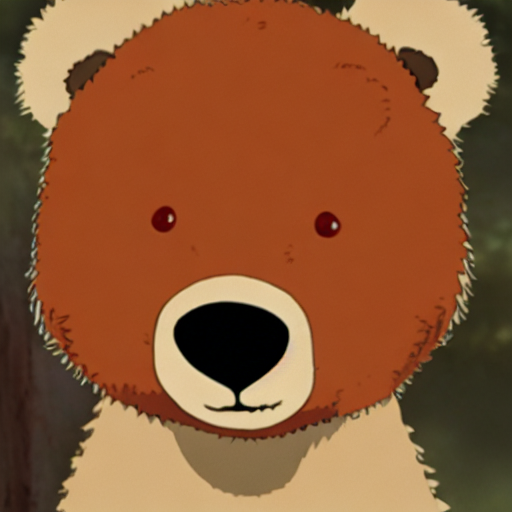

In [5]:
seed_everything(seed)

image = pipe(
    prompt,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
).images[0]

image
